# Step 2 — controlled checkpoint and class-weight experiment
Train the unchanged tabular MLP from scratch on the frozen 671 training users. Evaluate/select only on the frozen 144 validation users. No test parsing, threshold tuning, preprocessing refit, architecture changes, or pseudo-labeling. Preserve every existing baseline and Step-1 artifact.
Fixed before training: seeds 42/43/44, weights 1 / sqrt(training negative-to-positive ratio) / full ratio. Nine runs, 50 epochs each, paired initialization and RNG use. Threshold remains 0.5.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'configs/improvement_step2_v1.json').exists())
sys.path.insert(0, str(ROOT))
from src.checkpoint_weight_experiment import run, verify
from IPython.display import display, Image
print(ROOT)

C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation


## Fixed checkpoint policies
1. Last epoch (same epoch across arms).
2. Minimum weighted validation loss, preserving the historical mean-of-batch-means convention. This is a compatibility/sensitivity comparison.
3. Minimum unweighted validation BCE averaged over users: the primary common selection criterion across all class weights. Ties choose the earliest epoch.
Weight-specific loss values cannot rank different weight arms. F1/precision/recall/AUC/AP use identical validation users. Means and sample standard deviations over three paired seeds describe training variability, not confidence intervals or test generalization. The seed-42 full-weight control must reproduce the original history and selected/final validation predictions.

In [2]:
output_dir, validation_metrics, seed_summary = run(ROOT)
print('OUTPUT_VERSION:', output_dir)
display(validation_metrics)
display(seed_summary)

Training full_train_ratio, seed 42


seed=42 weight=4.122137 epoch=25: validation BCE=0.6179


seed=42 weight=4.122137 epoch=50: validation BCE=0.6221


Training sqrt_train_ratio, seed 42


seed=42 weight=2.030305 epoch=25: validation BCE=0.5102


...

seed=44 weight=1.000000 epoch=25: validation BCE=0.4445


seed=44 weight=1.000000 epoch=50: validation BCE=0.5184


OUTPUT_VERSION: C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\results\versions\improvement_step2_v1\20260920T114151695086Z_3c7db074


,seed,weight_rule,policy,epoch,n,bots,threshold,bot_precision,bot_recall,bot_f1,tn,fp,fn,tp,predicted_bots,roc_auc,average_precision,pos_weight,validation_weighted_loss,validation_unweighted_loss
0,42,full_train_ratio,last,50,144,28,0.5,0.346939,0.607143,0.441558,84,32,11,17,49,0.734606,0.450877,4.122137,1.308105,0.622062
1,42,full_train_ratio,best_weighted_validation_loss,9,144,28,0.5,0.375000,0.750000,0.500000,81,35,7,21,56,0.780172,0.484549,4.122137,0.918062,0.575254
2,42,full_train_ratio,best_unweighted_validation_loss,16,144,28,0.5,0.372549,0.678571,0.481013,84,32,9,19,51,0.774015,0.538977,4.122137,0.960951,0.549446
3,42,sqrt_train_ratio,last,50,144,28,0.5,0.468750,0.535714,0.500000,99,17,13,15,32,0.737377,0.459051,2.030305,0.827387,0.530787
4,42,sqrt_train_ratio,best_weighted_validation_loss,9,144,28,0.5,0.428571,0.428571,0.428571,100,16,16,12,28,0.761084,0.426882,2.030305,0.656955,0.463483
5,42,sqrt_train_ratio,best_unweighted_validation_loss,15,144,28,0.5,0.437500,0.500000,0.466667,98,18,14,14,32,0.765702,0.493977,2.030305,0.670980,0.456166
6,42,unweighted,last,50,144,28,0.5,0.444444,0.285714,0.347826,106,10,20,8,18,0.729064,0.403549,1.000000,0.537694,0.516634
7,42,unweighted,best_weighted_validation_loss,14,144,28,0.5,0.454545,0.178571,0.256410,110,6,23,5,11,0.751847,0.442241,1.000000,0.442825,0.429574
8,42,unweighted,best_unweighted_validation_loss,14,144,28,0.5,0.454545,0.178571,0.256410,110,6,23,5,11,0.751847,0.442241,1.000000,0.442825,0.429574
9,43,full_train_ratio,last,50,144,28,0.5,0.354167,0.607143,0.447368,85,31,11,17,48,0.730296,0.438211,4.122137,1.301616,0.594681


,weight_rule,policy,bot_f1_mean,bot_f1_std,bot_f1_min,bot_f1_max,bot_precision_mean,bot_precision_std,bot_precision_min,bot_precision_max,...,roc_auc_min,roc_auc_max,average_precision_mean,average_precision_std,average_precision_min,average_precision_max,epoch_mean,epoch_std,epoch_min,epoch_max
0,full_train_ratio,best_unweighted_validation_loss,0.461889,0.025886,0.432432,0.481013,0.368913,0.019524,0.347826,0.386364,...,0.745074,0.774015,0.504523,0.049462,0.447848,0.538977,24.000000,11.357817,16,37
1,full_train_ratio,best_weighted_validation_loss,0.458281,0.049044,0.404255,0.500000,0.337919,0.044983,0.287879,0.375000,...,0.746921,0.780172,0.472345,0.034164,0.433756,0.498731,8.666667,0.577350,8,9
2,full_train_ratio,last,0.446544,0.004628,0.441558,0.450704,0.357733,0.012951,0.346939,0.372093,...,0.730296,0.736145,0.472430,0.048714,0.438211,0.528202,50.000000,0.000000,50,50
3,sqrt_train_ratio,best_unweighted_validation_loss,0.465794,0.009249,0.456140,0.474576,0.445796,0.007376,0.437500,0.451613,...,0.746305,0.765702,0.475968,0.053295,0.416001,0.517925,13.333333,1.527525,12,15
4,sqrt_train_ratio,best_weighted_validation_loss,0.440287,0.011526,0.428571,0.451613,0.419897,0.008416,0.411765,0.428571,...,0.748461,0.761084,0.435409,0.038431,0.401957,0.477387,9.000000,1.000000,8,10
5,sqrt_train_ratio,last,0.480226,0.034250,0.440678,0.500000,0.462702,0.040661,0.419355,0.500000,...,0.730603,0.738608,0.465318,0.017916,0.451377,0.485525,50.000000,0.000000,50,50
6,unweighted,best_unweighted_validation_loss,0.280708,0.022222,0.256410,0.300000,0.556277,0.138714,0.454545,0.714286,...,0.739840,0.751847,0.449617,0.052323,0.401373,0.505237,11.000000,2.645751,9,14
7,unweighted,best_weighted_validation_loss,0.246076,0.059765,0.181818,0.300000,0.518182,0.074412,0.454545,0.600000,...,0.739840,0.751847,0.442224,0.040842,0.401373,0.483057,10.666667,3.055050,8,14
8,unweighted,last,0.423486,0.065872,0.347826,0.468085,0.549464,0.093819,0.444444,0.625000,...,0.727525,0.736145,0.432399,0.041188,0.403549,0.479569,50.000000,0.000000,50,50


,seed,weight_rule,policy,effect,delta_bot_f1,delta_bot_precision,delta_bot_recall,delta_roc_auc,delta_average_precision
0,42,full_train_ratio,last,weight_vs_full_same_policy,0.000000,0.000000,0.000000,0.000000,0.000000
1,42,full_train_ratio,last,checkpoint_vs_last_same_weight,0.000000,0.000000,0.000000,0.000000,0.000000
2,42,full_train_ratio,best_weighted_validation_loss,weight_vs_full_same_policy,0.000000,0.000000,0.000000,0.000000,0.000000
3,42,full_train_ratio,best_weighted_validation_loss,checkpoint_vs_last_same_weight,0.058442,0.028061,0.142857,0.045567,0.033672
4,42,full_train_ratio,best_unweighted_validation_loss,weight_vs_full_same_policy,0.000000,0.000000,0.000000,0.000000,0.000000
5,42,full_train_ratio,best_unweighted_validation_loss,checkpoint_vs_last_same_weight,0.039454,0.025610,0.071429,0.039409,0.088100
6,42,sqrt_train_ratio,last,weight_vs_full_same_policy,0.058442,0.121811,-0.071429,0.002771,0.008174
7,42,sqrt_train_ratio,last,checkpoint_vs_last_same_weight,0.000000,0.000000,0.000000,0.000000,0.000000
8,42,sqrt_train_ratio,best_weighted_validation_loss,weight_vs_full_same_policy,-0.071429,0.053571,-0.321429,-0.019089,-0.057668
9,42,sqrt_train_ratio,best_weighted_validation_loss,checkpoint_vs_last_same_weight,-0.071429,-0.040179,-0.107143,0.023707,-0.032170


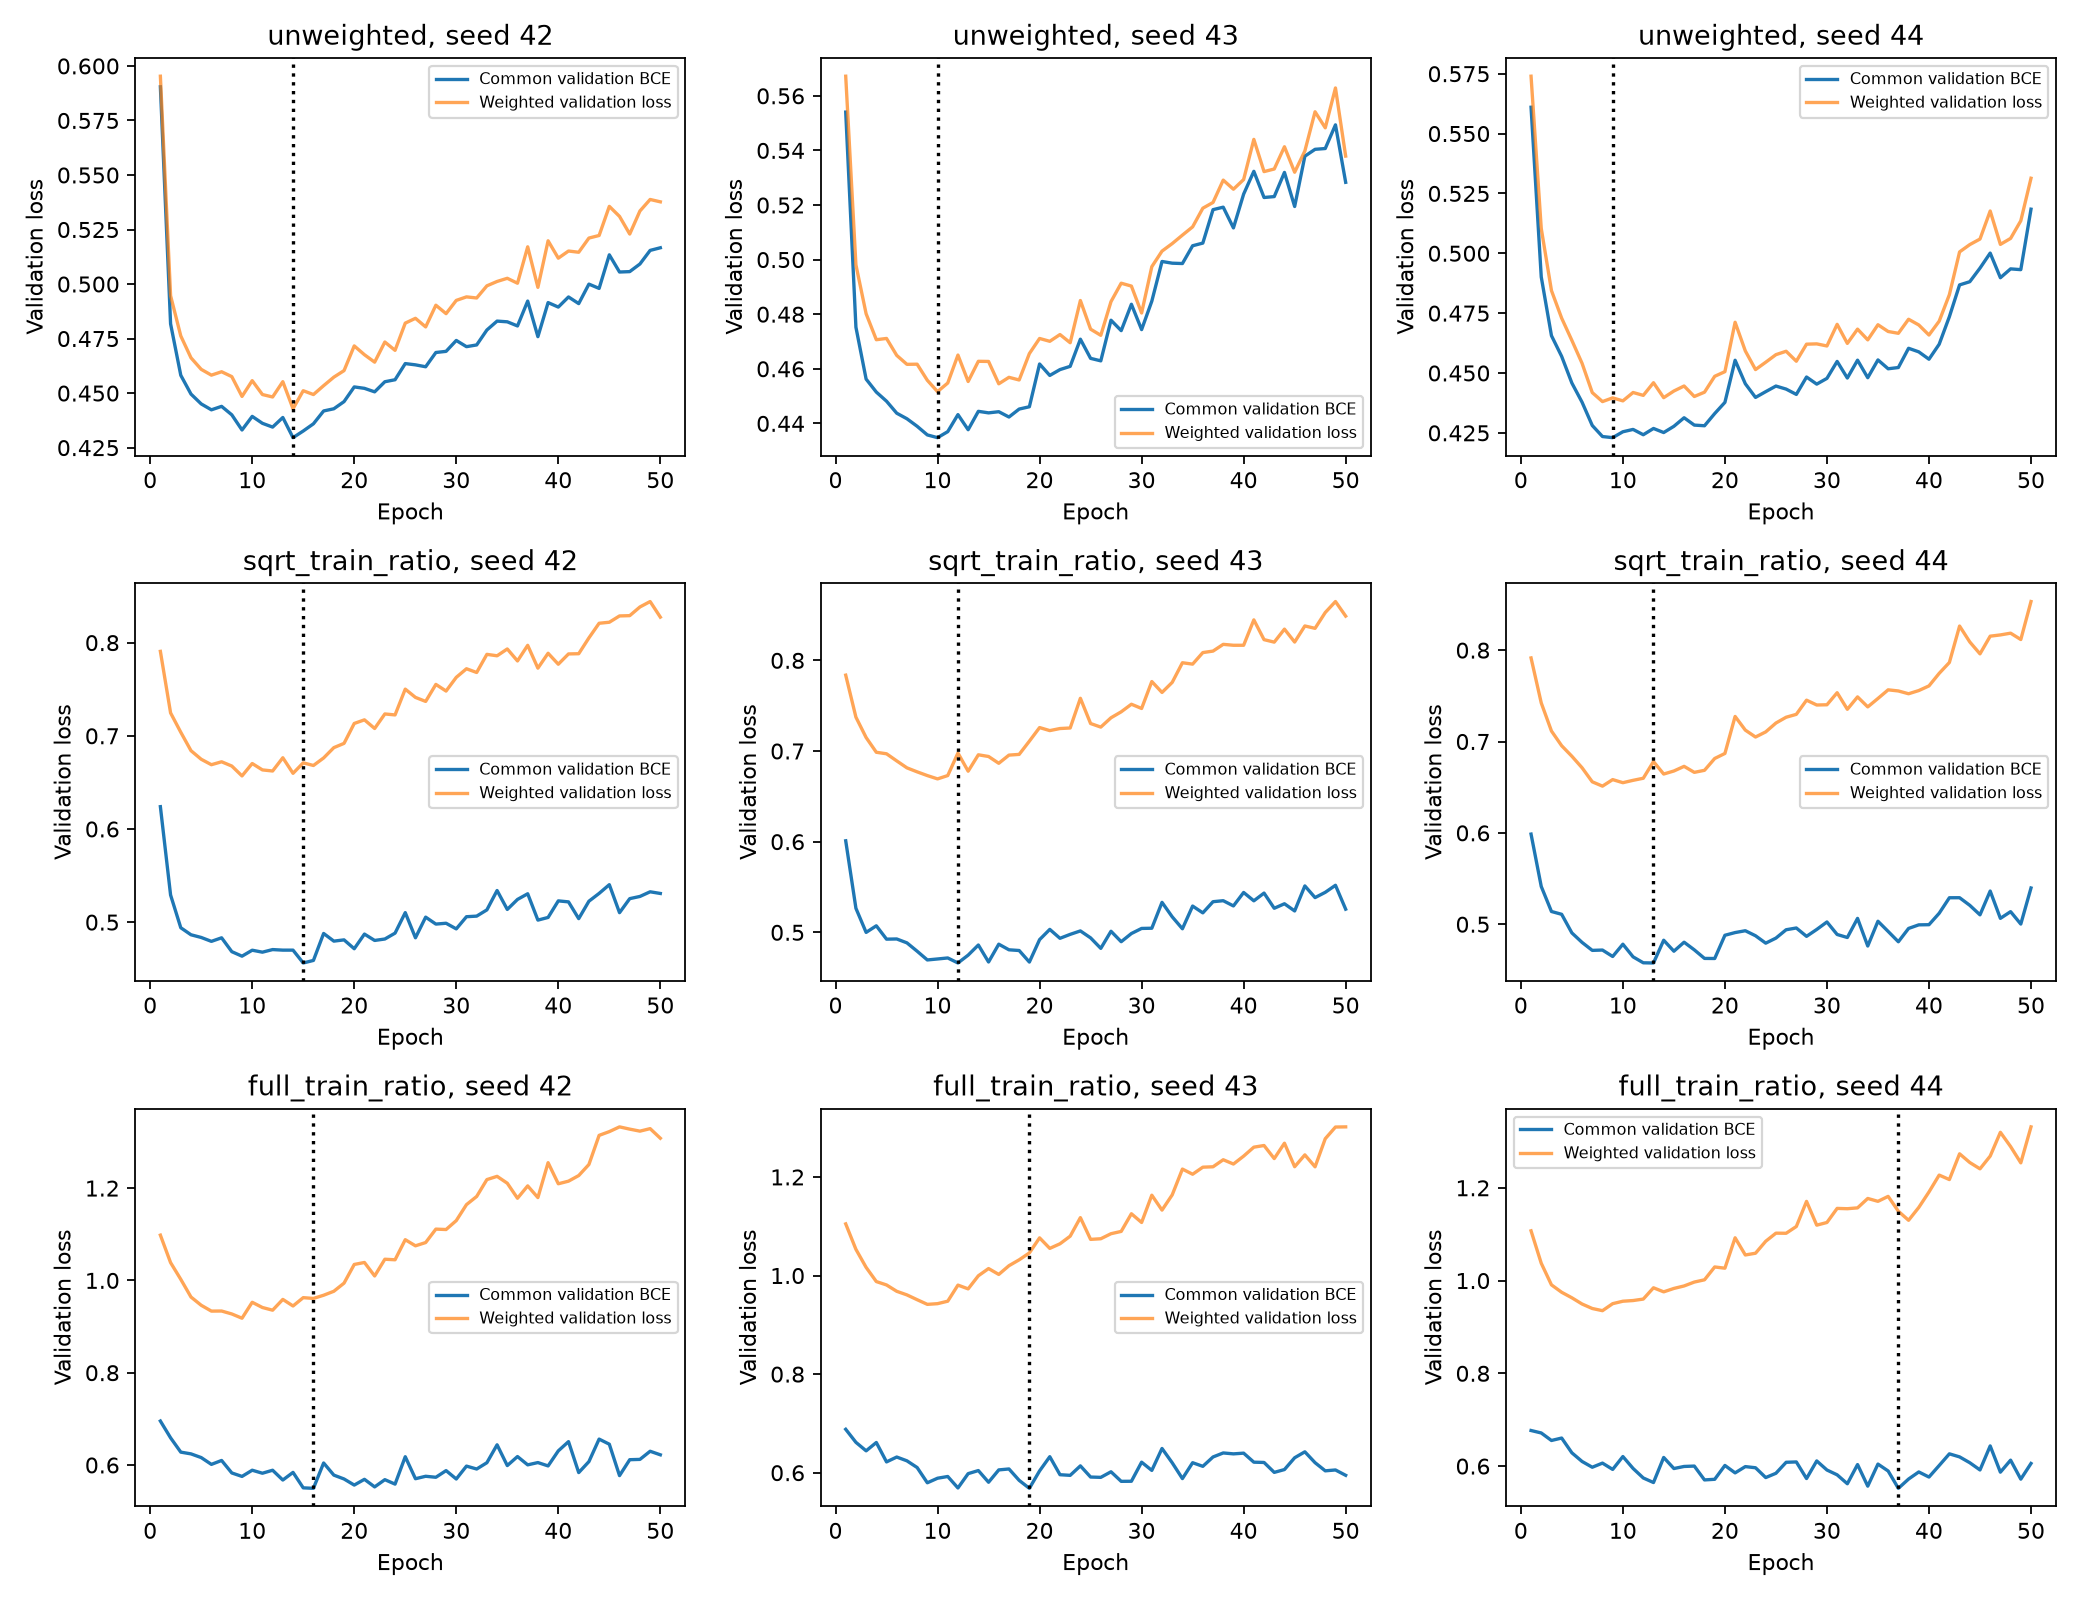

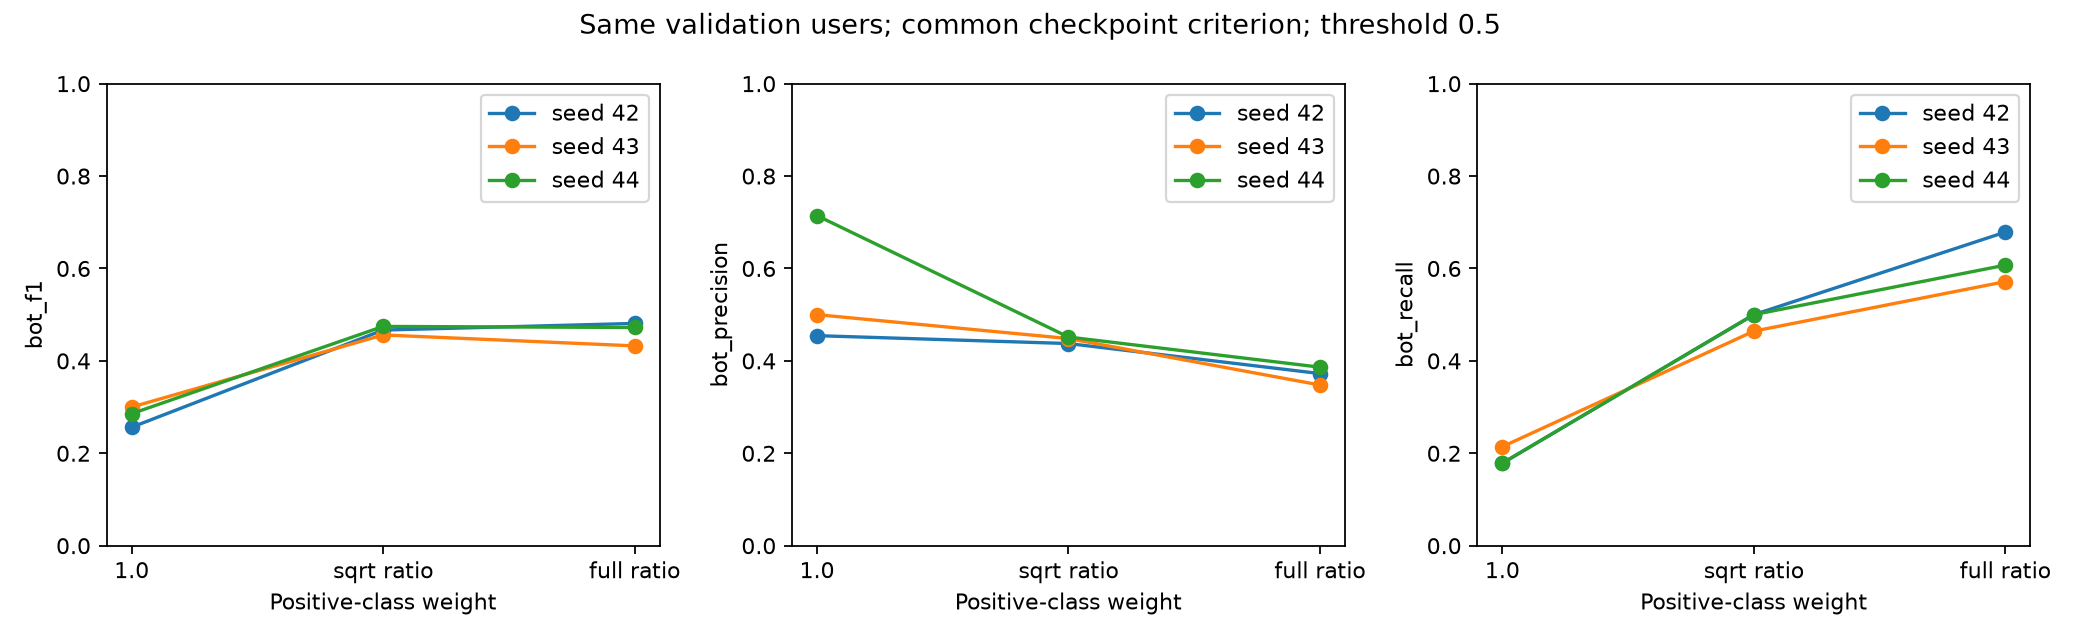

In [3]:
import pandas as pd
display(pd.read_csv(output_dir / 'paired_effects.csv'))
for path in sorted((output_dir / 'figures').glob('*.png')):
    display(Image(filename=str(path)))

In [4]:
verification = verify(ROOT, output_dir)
print(verification)

{'training_runs': 9, 'checkpoints_reloaded': 27, 'validation_prediction_files': 27, 'test_inputs_parsed': 0, 'baseline_control_reproduced': True, 'protected_files_at_execution': 569}


## Interpretation boundary
These are development-set experiments. The same validation set selects and evaluates checkpoints; comparisons remain selection-biased. Three seeds do not establish statistical significance. Weighted BCE changes both class emphasis and gradient scale; this is the effect of the implemented weighting policy, not an isolated explanation of its mechanism. No candidate is promoted to the baseline or final test protocol automatically. Review Step 2 before any architecture or semi-supervised change.